In [8]:
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    BASE_DIR = CURRENT_DIR.parent
elif (CURRENT_DIR / "src").exists():
    BASE_DIR = CURRENT_DIR
elif (CURRENT_DIR.parent / "src").exists():
    BASE_DIR = CURRENT_DIR.parent
else:
    raise FileNotFoundError(
        f"Không tìm thấy thư mục gốc project. Current directory: {CURRENT_DIR}"
    )

if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

os.chdir(BASE_DIR)

print(f"Thư mục làm việc: {BASE_DIR}")



Thư mục làm việc: d:\GitHub\ML-Kaggle-Project\cafe-revenue-regression


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

from sklearn.metrics import mean_squared_error

try:
    import lightgbm as lgb
except ImportError:
    lgb = None

try:
    import xgboost as xgb
except ImportError:
    xgb = None

try:
    import catboost as cb
except ImportError:
    cb = None

plt.style.use("ggplot")


pd.set_option("display.max_columns", None)

In [10]:
from src.data.load import load_raw_data
from src.data.validate import run_validation_pipeline
from src.data.join import build_feature_ready_data

raw_data = load_raw_data()
clean_data = run_validation_pipeline(raw_data)

train_df, test_df = build_feature_ready_data(clean_data)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("Train columns:", train_df.columns.tolist())
print("Test columns:", test_df.columns.tolist())

2026-10-25 21:35:24,098 - INFO - Starting Data Validation Pipeline...
2026-10-25 21:35:24,106 - INFO - Deduplication: Removed 132 duplicate rows from train data.


2026-10-25 21:35:24,145 - INFO - Missing-value handling completed. Weather shape: (1593, 4); stores shape: (45, 8)
2026-10-25 21:35:24,149 - INFO - Data Validation Pipeline Completed Successfully.
2026-10-25 21:35:24,256 - INFO - Join successful: 26500 rows, 15 columns
2026-10-25 21:35:24,258 - WARNING - sample_sub chỉ có id và revenue. Cần xác định quy tắc id trước khi tạo test data.


train        -> Shape: (26632, 4)
stores       -> Shape: (45, 8)
weather      -> Shape: (1593, 4)
holidays     -> Shape: (55, 3)
sample_sub   -> Shape: (3869, 2)
Train shape: (26500, 15)
Test shape: (3869, 2)
Train columns: ['date', 'store_id', 'is_promo', 'revenue', 'city', 'district', 'store_type', 'area_m2', 'seats', 'has_parking', 'open_date', 'temp_c', 'rain_mm', 'is_holiday', 'holiday_names']
Test columns: ['id', 'revenue']


In [11]:
if "date" not in train_df.columns:
    raise ValueError(
        "train_df không có cột date. "
        "Hãy sửa build_feature_ready_data() trong src/data/join.py "
        "để giữ lại cột date."
    )

train_df["date"] = pd.to_datetime(train_df["date"], errors="coerce")

if train_df["date"].isna().any():
    raise ValueError("Cột date có giá trị thiếu hoặc không chuyển được sang datetime.")

cutoff_date = pd.Timestamp("2025-10-01")

fit = train_df[train_df["date"] < cutoff_date].copy()
val = train_df[train_df["date"] >= cutoff_date].copy()

if fit.empty or val.empty:
    raise ValueError(
        "Tập fit hoặc validation đang rỗng. "
        "Hãy kiểm tra khoảng ngày trong dataset và điều chỉnh cutoff_date."
    )

print("Fit shape:", fit.shape)
print("Validation shape:", val.shape)

print("Fit period:", fit["date"].min(), "->", fit["date"].max())
print("Validation period:", val["date"].min(), "->", val["date"].max())

Fit shape: (22668, 15)
Validation shape: (3832, 15)
Fit period: 2024-01-01 00:00:00 -> 2025-09-30 00:00:00
Validation period: 2025-10-01 00:00:00 -> 2025-12-31 00:00:00


In [12]:
def rmsle(y, p):
    return np.sqrt(np.mean((np.log1p(np.clip(p, 0, None)) - np.log1p(y)) ** 2))

def weekday_median(history, target):
    h = history.assign(dow=history.date.dt.dayofweek)
    m = h.groupby(["store_id", "dow"]).revenue.median()
    
    keys = list(zip(target.store_id, target.date.dt.dayofweek))
    p = pd.Series(keys).map(m)
    
    store_med = target.store_id.map(h.groupby("store_id").revenue.median())
    p = p.fillna(store_med.reset_index(drop=True))
    
    return p.fillna(h.revenue.median()).values

baseline_preds = weekday_median(fit, val)
baseline_score = rmsle(val.revenue.values, baseline_preds)

print("validation RMSLE:", round(baseline_score, 5))

validation RMSLE: 0.23913


In [13]:
features = [ "is_promo", "area_m2", "seats", "has_parking", "temp_c", "rain_mm", "is_holiday", "store_id", ]

target = "revenue"

numeric_features = [ "is_promo","area_m2", "seats", "has_parking", "temp_c", "rain_mm", "is_holiday", ]

categorical_features = ["store_id"]


def prepare_features(df):
    missing = [f for f in features if f not in df.columns]

    if missing:
        raise ValueError(f"Thiếu feature trong dataset: {missing}")

    X = df[features].copy()

    X["store_id"] = X["store_id"].astype("string").fillna("UNKNOWN")

    X[numeric_features] = X[numeric_features].apply(
        pd.to_numeric,
        errors="coerce"
    )

    X[numeric_features] = X[numeric_features].replace(
        [np.inf, -np.inf],
        np.nan
    ).fillna(0)

    return X


X_fit = prepare_features(fit)
X_val = prepare_features(val)

y_fit = fit[target].to_numpy()
y_val = val[target].to_numpy()

print("Features:", features)
print("X_fit shape:", X_fit.shape)
print("X_val shape:", X_val.shape)

Features: ['is_promo', 'area_m2', 'seats', 'has_parking', 'temp_c', 'rain_mm', 'is_holiday', 'store_id']
X_fit shape: (22668, 8)
X_val shape: (3832, 8)


In [14]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "store",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features,
        )
    ],
    remainder="passthrough",
)

candidate_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=10.0),
    "Lasso Regression": Lasso(alpha=0.01, max_iter=10000),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=8,
        random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ),
}

if lgb is not None:
    candidate_models["LightGBM"] = lgb.LGBMRegressor(
        n_estimators=150,
        max_depth=6,
        learning_rate=0.05,
        random_state=42,
        verbosity=-1
    )

if xgb is not None:
    candidate_models["XGBoost"] = xgb.XGBRegressor(
        n_estimators=150,
        max_depth=6,
        learning_rate=0.05,
        random_state=42,
        n_jobs=-1
    )

if cb is not None:
    candidate_models["CatBoost"] = cb.CatBoostRegressor(
        iterations=150,
        depth=6,
        learning_rate=0.05,
        verbose=0,
        random_seed=42
    )

print("Số model:", len(candidate_models))
print(list(candidate_models.keys()))

Số model: 9
['Linear Regression', 'Ridge Regression', 'Lasso Regression', 'Decision Tree', 'Random Forest', 'Extra Trees', 'LightGBM', 'XGBoost', 'CatBoost']


In [15]:
results = []

# Thêm baseline
results.append({
    "Model": "Naive Store-Weekday Median",
    "Train RMSLE": rmsle(
        fit["revenue"].to_numpy(),
        weekday_median(fit, fit)
    ),
    "Validation RMSLE": baseline_score,
})

fitted_models = {}

for name, model in candidate_models.items():
    try:
        pipeline = Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("model", clone(model)),
        ])

        pipeline.fit(
            X_fit,
            np.log1p(np.clip(y_fit, 0, None))
        )

        train_preds = np.expm1(pipeline.predict(X_fit))
        val_preds = np.expm1(pipeline.predict(X_val))

        train_score = rmsle(y_fit, train_preds)
        val_score = rmsle(y_val, val_preds)

        fitted_models[name] = pipeline

        results.append({
            "Model": name,
            "Train RMSLE": train_score,
            "Validation RMSLE": val_score,
        })

        print(
            f"{name}: "
            f"Train RMSLE = {train_score:.5f} | "
            f"Validation RMSLE = {val_score:.5f}"
        )

    except Exception as e:
        print(f"{name} failed: {e}")

df_results = (
    pd.DataFrame(results)
    .sort_values("Validation RMSLE")
    .reset_index(drop=True)
)

df_results

Linear Regression: Train RMSLE = 0.39018 | Validation RMSLE = 0.29896
Ridge Regression: Train RMSLE = 0.39036 | Validation RMSLE = 0.29509
Lasso Regression: Train RMSLE = 0.45914 | Validation RMSLE = 0.36573
Decision Tree: Train RMSLE = 0.38153 | Validation RMSLE = 0.33976
Random Forest: Train RMSLE = 0.33831 | Validation RMSLE = 0.32720
Extra Trees: Train RMSLE = 0.37315 | Validation RMSLE = 0.31428
LightGBM: Train RMSLE = 0.36114 | Validation RMSLE = 0.30665
XGBoost: Train RMSLE = 0.34654 | Validation RMSLE = 0.31333
CatBoost: Train RMSLE = 0.37907 | Validation RMSLE = 0.29845


,Model,Train RMSLE,Validation RMSLE
0,Naive Store-Weekday Median,0.368429,0.239133
1,Ridge Regression,0.390361,0.295087
2,CatBoost,0.379070,0.298447
3,Linear Regression,0.390182,0.298956
4,LightGBM,0.361136,0.306646
5,XGBoost,0.346544,0.313327
6,Extra Trees,0.373149,0.314278
7,Random Forest,0.338313,0.327202
8,Decision Tree,0.381534,0.339763
9,Lasso Regression,0.459143,0.365733


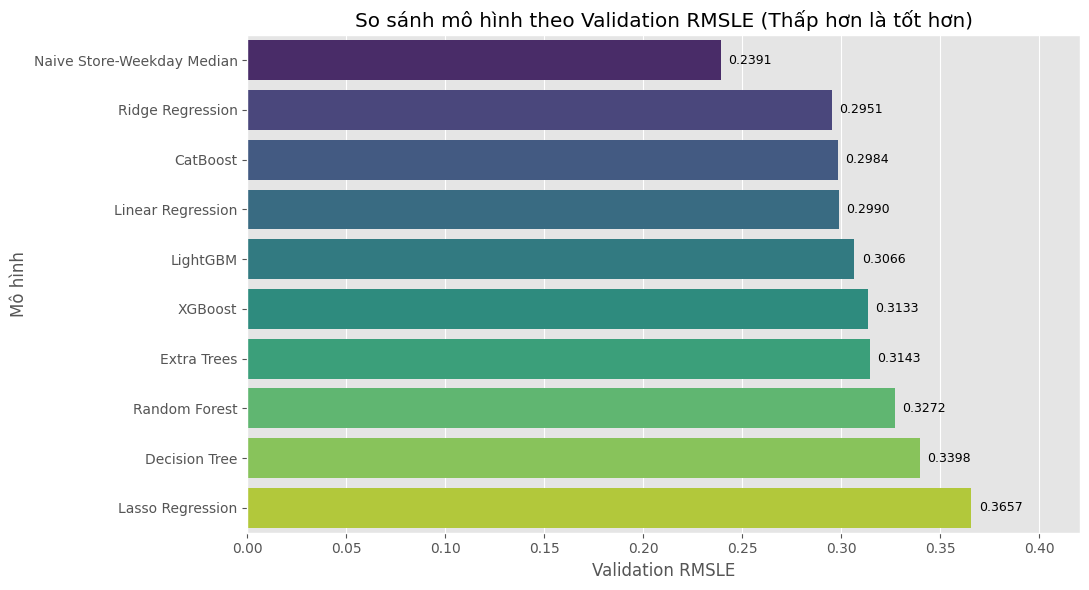

In [16]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=df_results,
    x="Validation RMSLE",
    y="Model",
    hue="Model",
    palette="viridis",
    legend=False,
)

plt.title("So sánh mô hình theo Validation RMSLE (Thấp hơn là tốt hơn)")
plt.xlabel("Validation RMSLE")
plt.ylabel("Mô hình")

max_score = df_results["Validation RMSLE"].max()
plt.xlim(0, max_score * 1.15 if max_score > 0 else 1)

for index, row in df_results.iterrows():
    plt.text(
        row["Validation RMSLE"] + max_score * 0.01,
        index,
        f"{row['Validation RMSLE']:.4f}",
        va="center",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

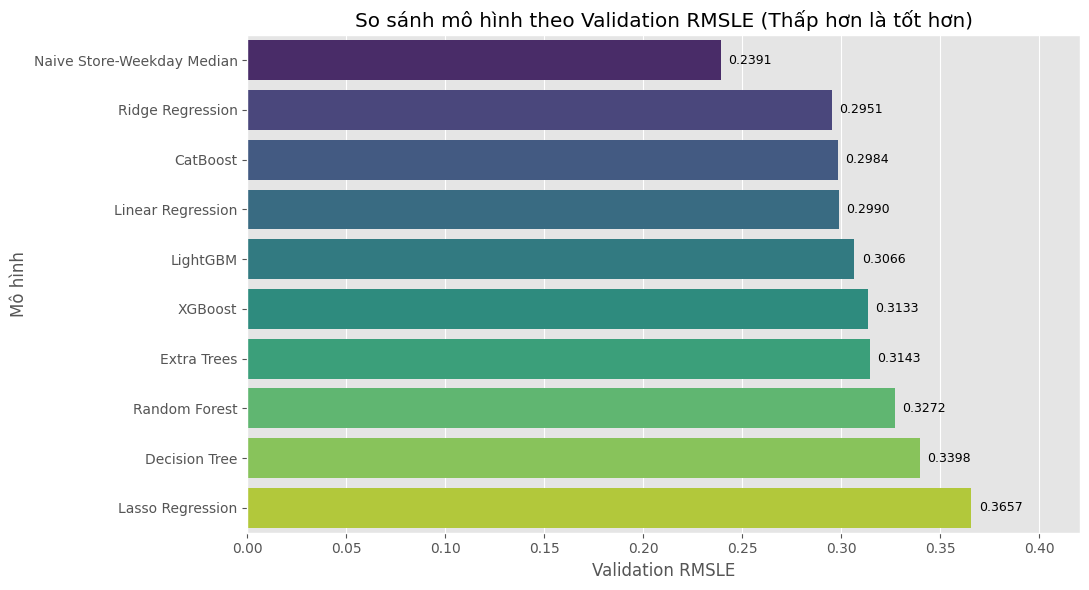

In [17]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=df_results,
    x="Validation RMSLE",
    y="Model",
    hue="Model",
    palette="viridis",
    legend=False,
)

plt.title("So sánh mô hình theo Validation RMSLE (Thấp hơn là tốt hơn)")
plt.xlabel("Validation RMSLE")
plt.ylabel("Mô hình")

max_score = df_results["Validation RMSLE"].max()
plt.xlim(0, max_score * 1.15 if max_score > 0 else 1)

for index, row in df_results.iterrows():
    plt.text(
        row["Validation RMSLE"] + max_score * 0.01,
        index,
        f"{row['Validation RMSLE']:.4f}",
        va="center",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

In [18]:
best_model_name = df_results.iloc[0]['Model']
print(f"Mô hình tốt nhất: {best_model_name}")

if best_model_name in fitted_models:
    best_pipeline = fitted_models[best_model_name]
    model_obj = best_pipeline.named_steps["model"]
    
    if hasattr(model_obj, 'feature_importances_'):
        # Lấy tên các cột sau khi qua OneHotEncoder
        prep = best_pipeline.named_steps["preprocessor"]
        cat_encoder = prep.named_transformers_["store"]
        ohe_cols = list(cat_encoder.get_feature_names_out(categorical_features))
        all_features = ohe_cols + numeric_features
        
        importances = model_obj.feature_importances_
        df_imp = pd.DataFrame({'Feature': all_features, 'Importance': importances})
        df_imp = df_imp.sort_values(by='Importance', ascending=False).head(15)
        
        plt.figure(figsize=(10, 5))
        sns.barplot(data=df_imp, x='Importance', y='Feature', palette='mako')
        plt.title(f'Top 15 Độ quan trọng đặc trưng ({best_model_name})')
        plt.tight_layout()
        plt.show()
    else:
        print("Mô hình này không hỗ trợ thuộc tính feature_importances_.")
else:
    print(f"Mô hình tốt nhất là {best_model_name} (Naive Baseline).")

Mô hình tốt nhất: Naive Store-Weekday Median
Mô hình tốt nhất là Naive Store-Weekday Median (Naive Baseline).


In [19]:
output_dir = BASE_DIR / "submissions"
output_dir.mkdir(parents=True, exist_ok=True)

if "id" not in test_df.columns:
    raise ValueError("test_df không có cột id để tạo submission.")

if best_model_name == "Naive Store-Weekday Median":
    if "date" in test_df.columns:
        test_preds = weekday_median(train_df, test_df)
    else:
        # Nếu test_df không có cột date, lấy median theo store_id hoặc overall median
        overall_median = train_df["revenue"].median()
        test_preds = np.full(len(test_df), overall_median)

else:
    X_full = prepare_features(train_df)
    y_full = train_df[target].to_numpy()

    final_model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", clone(candidate_models[best_model_name])),
    ])

    final_model.fit(
        X_full,
        np.log1p(np.clip(y_full, 0, None))
    )

    X_test = prepare_features(test_df)

    test_pred_log = final_model.predict(X_test)
    test_preds = np.expm1(test_pred_log)

sub_df = pd.DataFrame({
    "id": test_df["id"],
    "revenue": np.clip(test_preds, 0, None),
})

sub_path = output_dir / "submission_best_model.csv"
sub_df.to_csv(sub_path, index=False)

print(f"Đã xuất submission: {sub_path}")
print(sub_df.head())

Đã xuất submission: d:\GitHub\ML-Kaggle-Project\cafe-revenue-regression\submissions\submission_best_model.csv
       id    revenue
0  100000  18.280001
1  100001  18.280001
2  100002  18.280001
3  100003  18.280001
4  100004  18.280001
